In [ ]:
import numpy as np
import matplotlib.pyplot as plt

### **Generating a Linear Function with noise**

In [ ]:
W_true = 1.6
B_true = 2.9
spread = 8
N = 200
x_max = 10

X = np.random.rand(N) * x_max

spread_distr = (1 - abs((x_max/2) - X)/(x_max/1.6)) * (np.random.rand(N) * spread - spread/2)

Y = W_true * X + B_true + spread_distr


### **Plotting the Values**

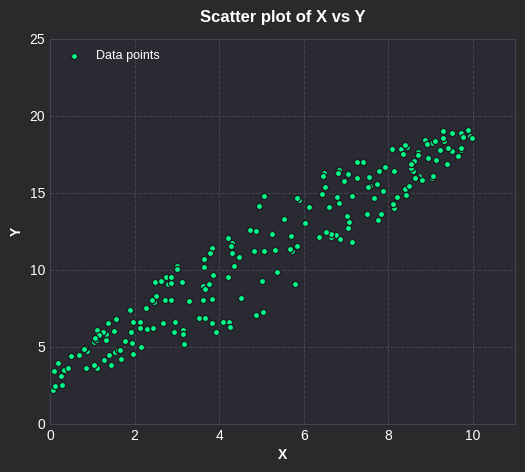

In [ ]:
# @title

fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(X, Y, color='#00ff88', edgecolor='#1e1e24', s=20, label='Data points', zorder=3)

ax.set_xlim(0, 11)
ax.set_ylim(0, 25)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Scatter plot of X vs Y')

ax.grid(True, zorder=1)

legend = ax.legend(labelcolor='white', loc='upper left')

plt.show()

###**Plotting the Mean Squared Error**
<font size="4">
$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - (w \cdot x_i + b))^2$$
</font>

* **Left Plot :** Change in MSE when the weight ($w$) is varying while the bias ($b$) is kept optimal.
    
* **Right Plot :** Change in MSE when the the bias ($b$) is varying while the weight ($w$) is kept optimal.



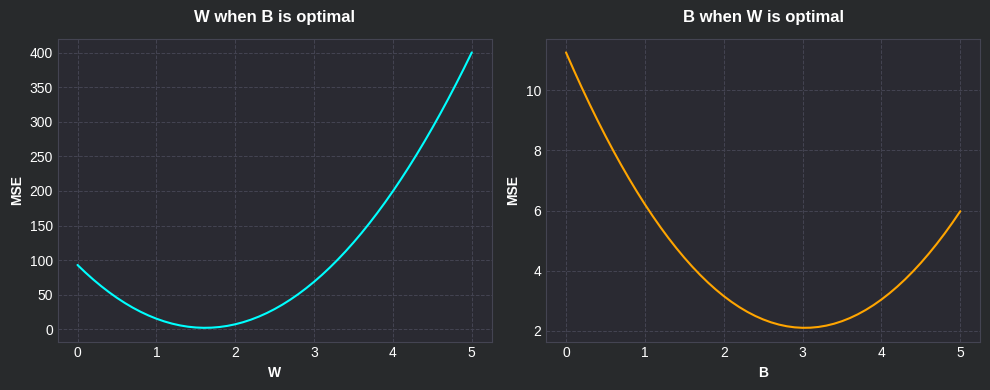

In [ ]:
# @title
w_values = np.arange(0, 5.1, 0.1)
b_values = np.arange(0, 5.1, 0.1)

MSE_w = np.array([])

for w in w_values:
  MSE_w = np.append(MSE_w, ((Y - (w * X + B_true))**2).mean())

MSE_b = np.array([])

for b in b_values:
  MSE_b = np.append(MSE_b, ((Y - (W_true * X + b))**2).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(w_values, MSE_w, color='cyan', label='W')
ax1.set_title('W when B is optimal')
ax1.set_xlabel('W')
ax1.set_ylabel('MSE')
ax1.grid(True)

ax2.plot(b_values, MSE_b, color='orange', label='B')
ax2.set_title('B when W is optimal')
ax2.set_xlabel('B')
ax2.set_ylabel('MSE')
ax2.grid(True)

plt.tight_layout()
plt.show()

### **Gradients with respect to $w$ and $b$**

$$\frac{\partial \text{MSE}}{\partial w} = -\frac{2}{N} \sum_{i=1}^{N} x_i (y_i - (w \cdot x_i + b)) \qquad
\frac{\partial \text{MSE}}{\partial b} = -\frac{2}{N} \sum_{i=1}^{N} (y_i - (w \cdot x_i + b))$$

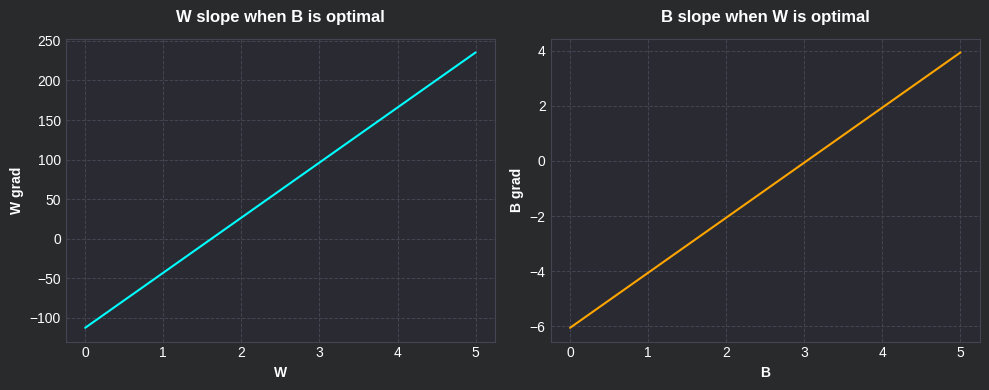

In [ ]:
# @title
w_grad = np.array([])

for w in w_values:
  w_grad = np.append(w_grad, (-2 * (Y - (w * X + B_true)) * X ).mean())

b_grad = np.array([])

for b in b_values:
  b_grad = np.append(b_grad, (-2 *(Y - (W_true * X + b))).mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(w_values, w_grad, color='cyan', label='W')
ax1.set_title('W slope when B is optimal')
ax1.set_xlabel('W')
ax1.set_ylabel('W grad')
ax1.grid(True)

ax2.plot(b_values, b_grad, color='orange', label='B')
ax2.set_title('B slope when W is optimal')
ax2.set_xlabel('B')
ax2.set_ylabel('B grad')
ax2.grid(True)

plt.tight_layout()
plt.show()


### **Training Linear Regression Model**

$$\begin{aligned}
w &\leftarrow w - \alpha \cdot \nabla w\\
b &\leftarrow b - \alpha \cdot \nabla b
\end{aligned}$$


In [ ]:
# @title
rnd = lambda x: round(x, 2)

def Loss(X, Y, w, b):
 return ((Y - (w * X + b))**2).mean()

def LinearRegression(X, Y , LearningRate= 0.001, epochs=5000):
  w = b = 0

  for epoch in range(epochs):
    Y_hat = w * X + b

    w_grad = (-2 * (Y - Y_hat) * X).mean()
    b_grad = (-2 * (Y - Y_hat)).mean()


    w = w - LearningRate * w_grad
    b = b - LearningRate * b_grad

    if (epoch %500 == 0):
      print(f"epoch : {rnd(epoch):>5},   w : {rnd(w):>4},   b : {rnd(b):>4},   Loss : {Loss(X, Y, w, b):>8.4f}")

  return w, b

w, b = LinearRegression(X, Y)
print("\nMean Squared Error : ", Loss(X, Y, w, b))


epoch :     0,   w : 0.14,   b : 0.02,   Loss : 129.6169
epoch :   500,   w : 1.91,   b :  0.9,   Loss :   3.2728
epoch :  1000,   w : 1.84,   b : 1.37,   Loss :   2.8163
epoch :  1500,   w : 1.79,   b : 1.74,   Loss :   2.5361
epoch :  2000,   w : 1.75,   b : 2.03,   Loss :   2.3641
epoch :  2500,   w : 1.71,   b : 2.26,   Loss :   2.2585
epoch :  3000,   w : 1.69,   b : 2.43,   Loss :   2.1937
epoch :  3500,   w : 1.67,   b : 2.57,   Loss :   2.1539
epoch :  4000,   w : 1.65,   b : 2.68,   Loss :   2.1295
epoch :  4500,   w : 1.64,   b : 2.77,   Loss :   2.1145

Mean Squared Error :  2.1052622394859104


### **Plotting the Predicted Line**

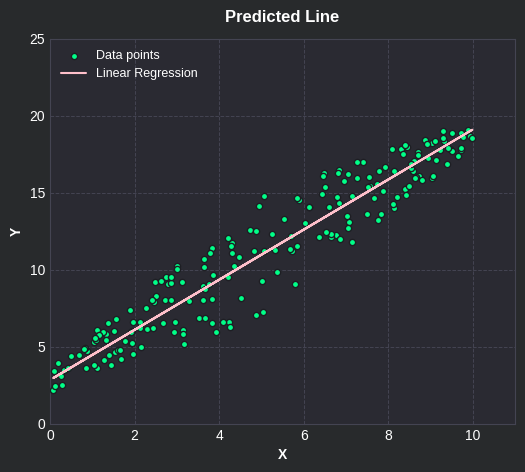

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(6, 5))

ax.scatter(X, Y, color='#00ff88', edgecolor='#1e1e24', s=20, label='Data points', zorder=3)
ax.plot(X, w * X + b, color='pink', label='Linear Regression', zorder=4)

ax.set_xlim(0, 11)
ax.set_ylim(0, 25)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Predicted Line')

ax.grid(True, zorder=1)

legend = ax.legend(labelcolor='white', loc='upper left')

plt.show()